In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.colors import CenteredNorm

from mg_sampling import PROJECT_DIR
from mg_sampling.density.grid import SparseGrid

from mg_sampling.density.plot import plot_map_slice

In [5]:
from collections import Counter

list(Counter("aaabcccabb").items())

[('a', 4), ('b', 3), ('c', 3)]

In [27]:
path = PROJECT_DIR / "density"

data = []
for filename in path.glob("*/mg/*.pkl"):
    weight_file = filename.with_stem(filename.stem + "_weight").with_suffix(".txt")
    if weight_file.exists():
        with open(weight_file, "r") as f:
            weight = float(f.read())
    else:
        weight = 1

    data.append(
        dict(
            sim=filename.parent.parent.name,
            block=filename.stem,
            filename=str(filename),
            map=SparseGrid.load(filename).to_dense(),
            weight=weight,
        )
    )
gen_maps = pd.DataFrame(data)
gen_maps["weight"] /= gen_maps.groupby("sim")["weight"].transform("sum")

In [28]:
gen_maps.iloc[10]['map'].grid.max()

np.float64(1.0098532217520255)

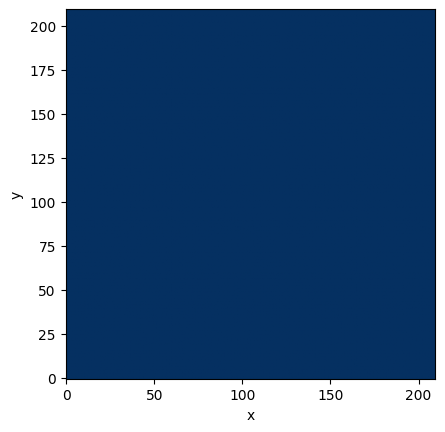

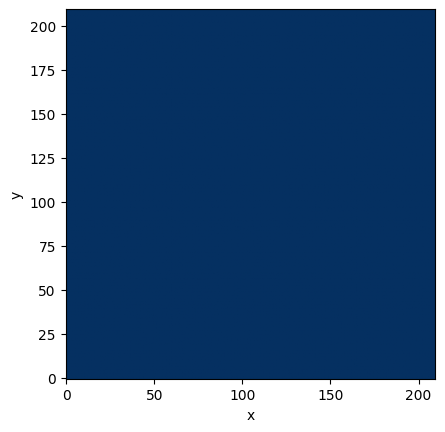

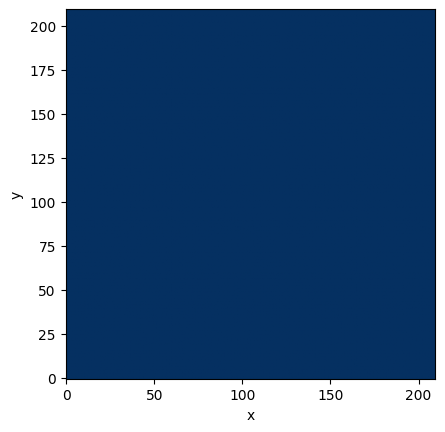

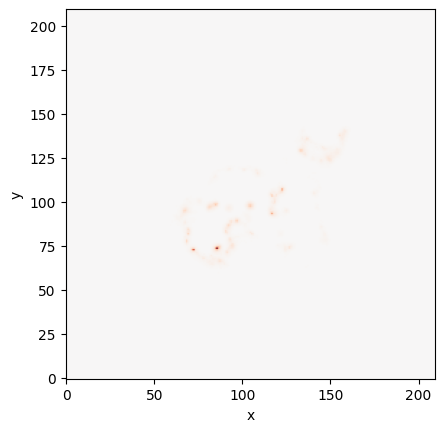

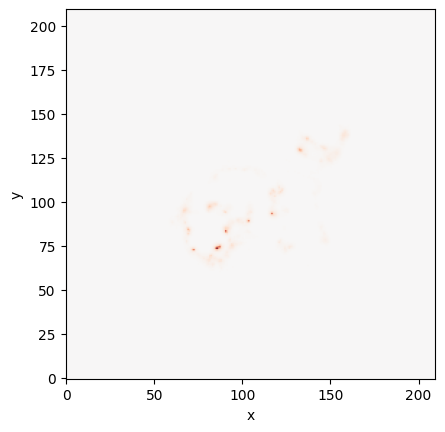

: 

In [ ]:
for sim, data in gen_maps.groupby('sim'):
    avg_map = np.average(data['map'], weights=data['weight'])
    plot_map_slice(avg_map, norm=CenteredNorm(), cmap="RdBu_r")
    plt.show()